# 3D Nested Gimbal Visualiser (Body Frame)

This notebook lets you play with the 2-DOF nested gimbal used in the 3D rocket model.

- **Outer gimbal**: yaw about the body +Z axis.
- **Inner gimbal**: pitch about the inner frame's +Y axis.
- The nozzle / thrust direction is expressed in the **body frame**, where:
  - +X is along the rocket nose,
  - +Y and +Z form the cross-section plane you see ("Apollo 8-ball" style).

Use the sliders to change the angles and see the resulting direction vector in the Y–Z plane.


In [2]:
# Setup: imports and helpers

import os
import sys
from typing import Tuple

import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from ipywidgets import interact

# Ensure we can import the project package when running this notebook directly
nb_dir = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
backend_dir = os.path.abspath(os.path.join(nb_dir, ".."))
src_dir = os.path.join(backend_dir, "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from simulacra.phenomena.actuators import _nozzle_direction_body  # type: ignore


def compute_dir_body(outer_deg: float, inner_deg: float) -> np.ndarray:
    """Compute body-frame nozzle direction for given gimbal angles (degrees).

    Args:
        outer_deg: Outer gimbal yaw about body +Z in degrees.
        inner_deg: Inner gimbal pitch about its +Y axis in degrees.
    """
    outer = np.deg2rad(outer_deg)
    inner = np.deg2rad(inner_deg)
    return _nozzle_direction_body(outer, inner)



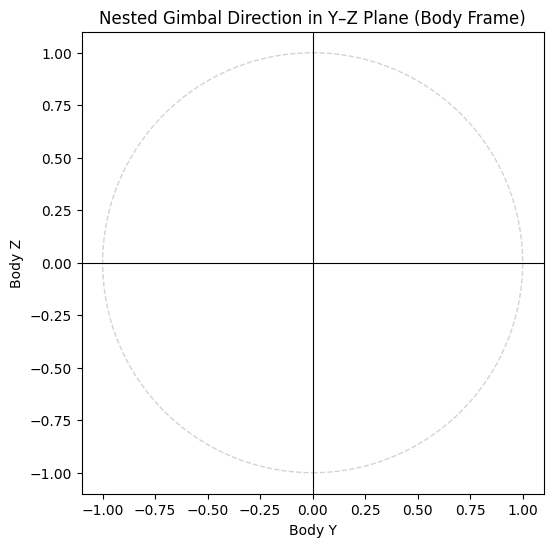

interactive(children=(FloatSlider(value=0.0, description='outer_yaw_z (deg)', max=60.0, min=-60.0, step=1.0), …

In [3]:
# Interactive "8-ball" style visualisation (looking down +X)

# We look at the Y-Z plane: Y horizontal, Z vertical.
# The nozzle direction projected into this plane is simply (d_y, d_z).

fig, ax = plt.subplots(figsize=(6, 6))

# Draw unit circle for reference
circle = plt.Circle((0, 0), 1.0, color="lightgray", fill=False, linestyle="--")
ax.add_patch(circle)

# Axes lines
ax.axhline(0, color="k", linewidth=0.8)
ax.axvline(0, color="k", linewidth=0.8)

# Initial direction
init_outer = 0.0
init_inner = 0.0
dir0 = compute_dir_body(init_outer, init_inner)

vec_line, = ax.plot([0, dir0[1]], [0, dir0[2]], color="magenta", linewidth=3)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Body Y")
ax.set_ylabel("Body Z")
ax.set_title("Nested Gimbal Direction in Y–Z Plane (Body Frame)")

# Text HUD inside the plot
hud_text = ax.text(
    0.02,
    0.98,
    "",
    transform=ax.transAxes,
    va="top",
    ha="left",
    family="monospace",
)


def update_plot(outer_deg: float, inner_deg: float):
    d = compute_dir_body(outer_deg, inner_deg)
    # Update vector in Y-Z plane
    vec_line.set_data([0, d[1]], [0, d[2]])

    hud_text.set_text(
        f"outer_yaw_z  = {outer_deg:6.2f}°\n"
        f"inner_pitch_y= {inner_deg:6.2f}°\n"
        f"dir_body     = [{d[0]:+6.3f}, {d[1]:+6.3f}, {d[2]:+6.3f}]"
    )
    fig.canvas.draw_idle()


outer_slider = widgets.FloatSlider(
    value=init_outer,
    min=-60.0,
    max=60.0,
    step=1.0,
    description="outer_yaw_z (deg)",
    continuous_update=True,
)
inner_slider = widgets.FloatSlider(
    value=init_inner,
    min=-45.0,
    max=45.0,
    step=1.0,
    description="inner_pitch_y (deg)",
    continuous_update=True,
)

widgets.interact(update_plot, outer_deg=outer_slider, inner_deg=inner_slider)

plt.show()


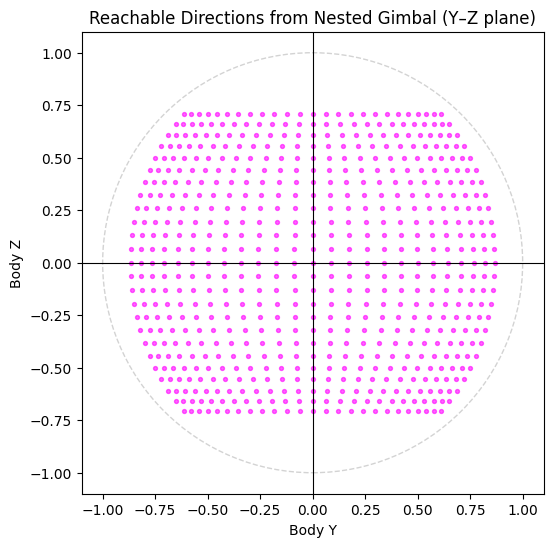

In [8]:
# Grid test: reachable directions in the Y–Z plane

# Define a grid of gimbal angles
outer_vals = np.linspace(-60.0, 60.0, 25)   # deg
inner_vals = np.linspace(-45.0, 45.0, 25)   # deg

points_y = []
points_z = []

for outer_deg in outer_vals:
    for inner_deg in inner_vals:
        d = compute_dir_body(outer_deg, inner_deg)
        points_y.append(d[1])
        points_z.append(d[2])

points_y = np.array(points_y)
points_z = np.array(points_z)

fig, ax = plt.subplots(figsize=(6, 6))

circle = plt.Circle((0, 0), 1.0, color="lightgray", fill=False, linestyle="--")
ax.add_patch(circle)
ax.axhline(0, color="k", linewidth=0.8)
ax.axvline(0, color="k", linewidth=0.8)

ax.scatter(points_y, points_z, s=8, alpha=0.6, color="magenta")

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Body Y")
ax.set_ylabel("Body Z")
ax.set_title("Reachable Directions from Nested Gimbal (Y–Z plane)")

plt.show()


In [ ]:
# Rocket trajectory visualisation under constant gimbal command

from simulacra.noumena import (
    Rocket,
    RocketProps,
    RocketState,
    Environment,
    Kernel,
    get_upright_orientation,
)
from simulacra.phenomena.actuators import GimbalActuator, GimbalCommand
from simulacra.physics import RocketVec3, WorldVec3


def simulate_trajectory(
    outer_deg: float,
    inner_deg: float,
    thrust: float = 80_000.0,
    duration: float = 8.0,
    dt: float = 0.02,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Simulate a simple 3D rocket under a fixed gimbal command.

    This uses the same `Kernel` and `GimbalActuator` as the main code,
    so we are testing the real integration and frame conventions.
    """
    props = RocketProps(
        length=6.0,
        mass=120.0,
        center_of_mass_offset=RocketVec3(0.0, 0.0, 0.0),
        inertia_diag=(50.0, 50.0, 10.0),
        thrust_application_offset=RocketVec3(0.0, 0.0, 0.0),
    )

    state = RocketState(
        position=WorldVec3(0.0, 0.0, 0.0),
        velocity=WorldVec3(0.0, 0.0, 0.0),
        orientation=get_upright_orientation(),
        angular_velocity_body=RocketVec3(0.0, 0.0, 0.0),
        thrust_body=RocketVec3(thrust, 0.0, 0.0),
    )

    rocket = Rocket(props=props, state=state)
    env = Environment()
    kernel = Kernel(rocket=rocket, environment=env)

    actuator = GimbalActuator(
        rocket=rocket,
        max_outer_angle=np.deg2rad(60.0),
        max_inner_angle=np.deg2rad(45.0),
    )

    n_steps = int(duration / dt)
    xs: list[float] = []
    ys: list[float] = []
    zs: list[float] = []

    for _ in range(n_steps):
        cmd = GimbalCommand(
            desired_outer_angle=np.deg2rad(outer_deg),
            desired_inner_angle=np.deg2rad(inner_deg),
        )
        actuator.apply(cmd)
        kernel.step(dt)
        pos = rocket.state.position
        xs.append(pos.x)
        ys.append(pos.y)
        zs.append(pos.z)

    return np.array(xs), np.array(ys), np.array(zs)


# 3D trajectory plot
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

fig_traj = plt.figure(figsize=(7, 6))
ax_traj = fig_traj.add_subplot(111, projection="3d")
traj_line, = ax_traj.plot([], [], [], "b-", linewidth=2)

ax_traj.set_xlabel("World X")
ax_traj.set_ylabel("World Y (up)")
ax_traj.set_zlabel("World Z")
ax_traj.set_title("Rocket Trajectory under Constant Gimbal Command")


def set_equal_3d(ax):
    max_range = 1.0
    ax.set_xlim(-max_range, max_range)
    ax.set_ylim(0.0, 1.5 * max_range)
    ax.set_zlim(-max_range, max_range)
    ax.set_box_aspect((1, 1.5, 1))


def update_traj(outer_deg: float, inner_deg: float):
    xs, ys, zs = simulate_trajectory(outer_deg, inner_deg)

    traj_line.set_data(xs, ys)
    traj_line.set_3d_properties(zs)

    # Autoscale based on trajectory extent, with some padding
    if xs.size > 0:
        pad = 0.1 * max(1.0, float(np.max(np.abs([xs, ys, zs]))))
        ax_traj.set_xlim(float(xs.min()) - pad, float(xs.max()) + pad)
        ax_traj.set_ylim(float(ys.min()) - pad, float(ys.max()) + pad)
        ax_traj.set_zlim(float(zs.min()) - pad, float(zs.max()) + pad)

    fig_traj.canvas.draw_idle()


outer_traj_slider = widgets.FloatSlider(
    value=0.0,
    min=-60.0,
    max=60.0,
    step=2.0,
    description="outer_yaw_z (deg)",
    continuous_update=False,
)
inner_traj_slider = widgets.FloatSlider(
    value=0.0,
    min=-45.0,
    max=45.0,
    step=2.0,
    description="inner_pitch_y (deg)",
    continuous_update=False,
)

widgets.interact(update_traj, outer_deg=outer_traj_slider, inner_deg=inner_traj_slider)

plt.show()